# Pitfalls in AI Self-Improvement — figures

Prose draft lives in [`drafts/blog/2026-09-23-pitfalls-in-ai-self-improvement.md`](../../drafts/blog/2026-09-23-pitfalls-in-ai-self-improvement.md).

Use this notebook for graphs/figures only. Export images to `public/assets/img/notebooks/pitfalls-in-ai-self-improvement/` and reference them from the markdown draft.


In [268]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

# notebooks/ on path so we can import palettes.py
sys.path.insert(0, str(Path("..").resolve()))
from palettes import load_palette, palette_cycle

p = load_palette("hinoki_forest")
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=palette_cycle("hinoki_forest"))

FIG_DIR = Path("../../public/assets/img/notebooks/pitfalls-in-ai-self-improvement")
FIG_DIR.mkdir(parents=True, exist_ok=True)

p  # mist_sky, hinoki_bark, moss_light, cedar_needle, forest_shade, deep_grove, stone_path, ember_clay


namespace(mist_sky='#E8F1EC',
          hinoki_bark='#CDBB9C',
          moss_light='#B7C9A0',
          cedar_needle='#7E9A72',
          forest_shade='#4E6B53',
          deep_grove='#2F4A3C',
          stone_path='#8F8A7A',
          ember_clay='#A66A53')

## Figures


In [269]:
# Example:
# fig, ax = plt.subplots()
# ax.plot(x, y, color=p.ember_clay)
# ax.axhline(0, color=p.stone_path, lw=0.8)
# fig.savefig(FIG_DIR / "figure-1.png", dpi=150, bbox_inches="tight")


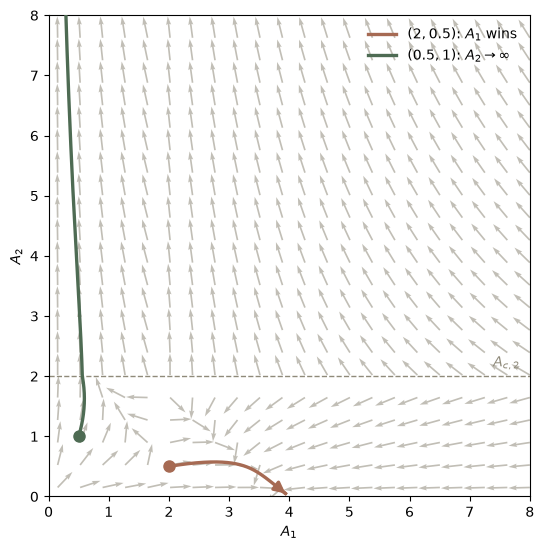

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

forest_shade = p.forest_shade
ember_clay = p.ember_clay
stone_path = p.stone_path

c1 = c2 = H = 1.0
Ac1, Ac2 = 2.0, 2.0
rho11, delta1 = 0.20, 0.45  # A1 finite alone
rho22, delta2 = 0.55, 0.30  # A2 runaway alone past Ac2

# trajectory starts — dots are plotted from these
start_a1 = (2.0, 0.5)  # A1 wins
start_a2 = (0.5, 1.0)  # A2 → ∞

def r(A, Ac, rho):
    A = np.asarray(A, dtype=float)
    out = np.zeros_like(A)
    m = A >= Ac
    out[m] = rho * A[m]
    return out

def Adot(A1, A2):
    s = A1 + A2
    s = np.where(s < 1e-12, 1.0, s)
    H1, H2 = H * A1 / s, H * A2 / s
    dA1 = c1 * H1 + r(A1, Ac1, rho11) - delta1 * A1
    dA2 = c2 * H2 + r(A2, Ac2, rho22) - delta2 * A2
    return dA1, dA2

xmax = ymax = 8.0
n = 22
AA1, AA2 = np.meshgrid(
    np.linspace(0.15, xmax, n),
    np.linspace(0.15, ymax, n),
)
U, V = Adot(AA1, AA2)
spd = np.hypot(U, V)
spd = np.where(spd < 1e-12, 1.0, spd)

def rk4_traj(a1, a2, t_end=60.0, dt=0.04):
    nstep = int(t_end / dt)
    out = np.empty((nstep + 1, 2))
    out[0] = (a1, a2)
    for i in range(nstep):
        y = out[i]
        f = lambda z: np.array(Adot(z[0], z[1]), dtype=float)
        k1 = f(y)
        k2 = f(y + 0.5 * dt * k1)
        k3 = f(y + 0.5 * dt * k2)
        k4 = f(y + dt * k3)
        nxt = y + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        nxt[0] = max(nxt[0], 0.0)
        nxt[1] = max(nxt[1], 0.0)
        out[i + 1] = nxt
        if nxt[0] > xmax * 1.2 or nxt[1] > ymax * 1.2:
            return out[: i + 2]
    return out

def tip_in_frame(tr, xmax, ymax):
    """Last point still inside the axes window (for arrowheads)."""
    inside = (tr[:, 0] <= xmax) & (tr[:, 1] <= ymax)
    idx = np.where(inside)[0]
    i = int(idx[-1]) if len(idx) else len(tr) - 1
    i0 = max(i - 1, 0)
    return tr[i0], tr[i]

fig, ax = plt.subplots(figsize=(6.2, 5.6))

ax.quiver(
    AA1, AA2, U / spd, V / spd,
    color=stone_path, alpha=0.55, angles="xy",
    scale_units="xy", scale=2.8, width=0.0035, zorder=1,
)

tr1 = rk4_traj(*start_a1)
tr2 = rk4_traj(*start_a2)

ax.plot(tr1[:, 0], tr1[:, 1], color=ember_clay, lw=2.4, zorder=3,
        label=rf"$({start_a1[0]:g},{start_a1[1]:g})$: $A_1$ wins")
ax.plot(tr2[:, 0], tr2[:, 1], color=forest_shade, lw=2.4, zorder=3,
        label=rf"$({start_a2[0]:g},{start_a2[1]:g})$: $A_2\to\infty$")

# start dots from the same params as the trajectories
ax.plot(*start_a1, "o", color=ember_clay, ms=8, zorder=4)
ax.plot(*start_a2, "o", color=forest_shade, ms=8, zorder=4)

# arrowhead at the visible tip of the orange (A1) trajectory
p0, p1 = tip_in_frame(tr1, xmax, ymax)
ax.annotate(
    "",
    xy=p1, xytext=p0,
    arrowprops=dict(
        arrowstyle="-|>",
        color=ember_clay,
        lw=2.4,
        mutation_scale=16,
        shrinkA=0,
        shrinkB=0,
    ),
    zorder=5,
)

ax.axhline(Ac2, color=stone_path, ls="--", lw=1)
ax.text(xmax * 0.98, Ac2 + 0.15, r"$A_{c,2}$", color=stone_path,
        ha="right", fontsize=10)

ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)
ax.set_xlabel(r"$A_1$")
ax.set_ylabel(r"$A_2$")
ax.legend(frameon=False, loc="upper right")
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
fig.savefig(FIG_DIR / "rsi_two_model_threshold.png", dpi=300, bbox_inches="tight")


/var/folders/tl/s9l9pxb94k55xwd5rsvc51nm0000gn/T/ipykernel_61610/2567735272.py:3: RuntimeWarning: divide by zero encountered in log
  y1 = 0.2 + 0.5 *  x + .05 *(np.log(x))


Text(0, 0.5, 'Dimension 2')

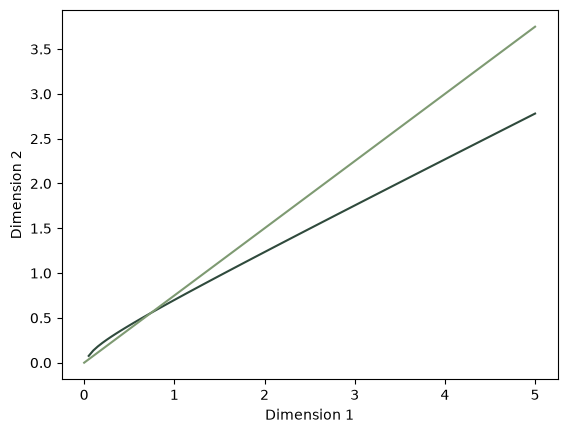

In [ ]:
x = np.linspace(0, 5, 100)

y1 = 